# Cuaderno 02 — Ejercicio 1 (CART vs. regresión logística) y Ejercicio 2 (árboles de regresión vs. regresión lineal)

**Tarea de ejecución 03 — Aplicar modelos CART y ensamblados**

**Curso:** Aprendizaje de Máquina (UNAP, IX ciclo, grupo B)
**Docente:** Ing. Fernández Chambi Mayenka
**Estudiante:** Cristian Junior Cunurana Calderón

---

## Objetivos

- **Ejercicio 1.** Entrenar modelos de árboles de decisión con dos criterios de impureza
  (`gini` y `entropy`) sobre el conjunto `breast_cancer` y comparar su eficiencia con la de
  un modelo lineal, la **regresión logística**. Determinar cuál es mejor.
- **Ejercicio 2.** Entrenar modelos de árboles de decisión con distintas configuraciones de
  hiperparámetros sobre el conjunto `auto_mpg` y comparar su eficiencia con la de la
  **regresión lineal**. Determinar cuál es mejor.

## Protocolo experimental

| Aspecto | Decisión adoptada |
|---|---|
| Partición | 80 % entrenamiento / 20 % prueba, estratificada en clasificación, semilla 42 |
| Validación | 5 particiones (`StratifiedKFold` / `KFold`), `shuffle=True`, semilla 42 |
| Selección | `GridSearchCV` **solo sobre el conjunto de entrenamiento** |
| Métricas (clasificación) | Exactitud, precisión, exhaustividad, F1 y AUC-ROC, con la clase *maligno* como positiva |
| Métricas (regresión) | RMSE, MAE y $R^2$ |
| Preprocesamiento | Incluido dentro de `Pipeline`; se ajusta únicamente con datos de entrenamiento |
| Comparaciones | Todos los modelos se evalúan sobre **las mismas** observaciones de prueba |

El conjunto de prueba no participa en ninguna decisión de ajuste ni de selección de
hiperparámetros.

In [1]:
import sys
import time
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd() / "cuadernos"))
if not (Path.cwd() / "cuadernos" / "comun.py").exists():
    sys.path.insert(0, str(Path.cwd().parent / "cuadernos"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    auc,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    StratifiedKFold,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text

from comun import (
    RAIZ,
    SEMILLA,
    PALETA,
    aplicar_estilo,
    cargar_auto_mpg,
    cargar_breast_cancer,
    fijar_semilla,
    guardar_csv,
    guardar_json,
)

warnings.filterwarnings("ignore", category=FutureWarning)
aplicar_estilo()
fijar_semilla(SEMILLA)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)

FIG = RAIZ / "figuras"
RES = RAIZ / "resultados"
print("RAIZ:", RAIZ)

RAIZ: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 3


## Parte I — Ejercicio 1: criterios de impureza frente a la regresión logística

### 1.1 Preparación de los datos

Se recupera la partición definida en el cuaderno 01: 455 observaciones de entrenamiento y
114 de prueba, con estratificación por clase.

In [2]:
X_bc, y_bc, nombres_bc = cargar_breast_cancer()

X_tr, X_te, y_tr, y_te = train_test_split(
    X_bc, y_bc, test_size=0.20, random_state=SEMILLA, stratify=y_bc
)

cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

print(f"Entrenamiento: {X_tr.shape[0]} | Prueba: {X_te.shape[0]}")
print(f"Malignos — entrenamiento: {int(y_tr.sum())} | prueba: {int(y_te.sum())}")
print(f"Beningos — prueba: {int((y_te == 0).sum())}")

Entrenamiento: 455 | Prueba: 114
Malignos — entrenamiento: 285 | prueba: 72
Beningos — prueba: 42


### 1.2 Definición de los modelos y de las redes de búsqueda

**Árboles de decisión.** Para cada criterio de impureza se 탐rea una malla de
profundidades máximas {2, 3, 4, 5, 8, sin límite} y mínimos de muestras por hoja
{1, 3, 5, 10}: 24 configuraciones por criterio, 48 en total.

**Regresión logística.** Se estandarizan las variables dentro de un `Pipeline` (el modelo
lineal es sensible a la escala) y se ajustan seis valores del parámetro de regularización
$C \in \{0.01, 0.1, 1, 10, 100, 1000\}$ con 5000 iteraciones máximas.

**Referencia.** Se añade un clasificador *dummy* que predice siempre la clase mayoritaria;
sirve para saber cuánto aporta realmente el aprendizaje.

In [3]:
CV_ESTABLE = {"n_jobs": -1, "cv": cv_clf, "scoring": "f1", "refit": True,
              "return_train_score": False}

profundidades = [2, 3, 4, 5, 8, None]
minimos_hoja = [1, 3, 5, 10]

resultados_busqueda = {}
modelos = {}

for criterio in ["gini", "entropy"]:
    arbol = DecisionTreeClassifier(criterion=criterio, random_state=SEMILLA)
    malla = {"max_depth": profundidades, "min_samples_leaf": minimos_hoja}
    busqueda = GridSearchCV(arbol, malla, **CV_ESTABLE)
    t0 = time.perf_counter()
    busqueda.fit(X_tr, y_tr)
    t1 = time.perf_counter()
    resultados_busqueda[criterio] = busqueda
    modelos[f"arbol_{criterio}"] = busqueda.best_estimator_
    print(f"[{criterio}] mejor F1 CV = {busqueda.best_score_:.4f} | {busqueda.best_params_} "
          f"| tiempo = {t1 - t0:.2f} s")

# Regresión logística con estandarización
pipe_log = Pipeline([
    ("escalador", StandardScaler()),
    ("clasificador", LogisticRegression(max_iter=5000, random_state=SEMILLA)),
])
malla_log = {"clasificador__C": [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]}
busqueda_log = GridSearchCV(pipe_log, malla_log, **CV_ESTABLE)
t0 = time.perf_counter()
busqueda_log.fit(X_tr, y_tr)
t1 = time.perf_counter()
modelos["regresion_logistica"] = busqueda_log.best_estimator_
resultados_busqueda["regresion_logistica"] = busqueda_log
print(f"[logística] mejor F1 CV = {busqueda_log.best_score_:.4f} | {busqueda_log.best_params_} "
      f"| tiempo = {t1 - t0:.2f} s")

# Referencia dummy
dummy = DummyClassifier(strategy="most_frequent", random_state=SEMILLA)
dummy.fit(X_tr, y_tr)
modelos["dummy"] = dummy
print("[dummy] clase mayoritaria:", dummy.classes_)

[gini] mejor F1 CV = 0.9460 | {'max_depth': 3, 'min_samples_leaf': 5} | tiempo = 2.58 s
[entropy] mejor F1 CV = 0.9509 | {'max_depth': 4, 'min_samples_leaf': 5} | tiempo = 0.16 s


[logística] mejor F1 CV = 0.9861 | {'clasificador__C': 0.1} | tiempo = 0.06 s
[dummy] clase mayoritaria: [0 1]


### 1.3 Resultados de la validación cruzada para el árbol

Se listan las 24 configuraciones evaluadas para cada criterio, ordenadas de mayor a menor
F1 medio de validación. Esta tabla documenta que la selección no fue arbitraria.

In [4]:
tablas_cv = []
for criterio, busqueda in [("gini", resultados_busqueda["gini"]),
                           ("entropy", resultados_busqueda["entropy"])]:
    df_cv = pd.DataFrame(busqueda.cv_results_)[["param_max_depth", "param_min_samples_leaf",
                                                  "mean_test_score", "std_test_score", "rank_test_score"]]
    df_cv.columns = ["max_depth", "min_samples_leaf", "f1_cv_medio", "f1_cv_de", "ranking"]
    df_cv.insert(0, "criterio", criterio)
    tablas_cv.append(df_cv)

tabla_cv_arboles = pd.concat(tablas_cv, ignore_index=True)
tabla_cv_arboles = tabla_cv_arboles.sort_values(["criterio", "ranking"])
display(tabla_cv_arboles.head(12).reset_index(drop=True))
guardar_csv(tabla_cv_arboles, "ejercicio1_cv_arboles.csv")

,criterio,max_depth,min_samples_leaf,f1_cv_medio,f1_cv_de,ranking
0,entropy,4,5,0.950883,0.015357,1
1,entropy,3,5,0.948223,0.017961,2
2,entropy,3,1,0.947973,0.018223,3
3,entropy,3,3,0.947973,0.018223,3
4,entropy,4,1,0.947194,0.011111,5
5,entropy,4,3,0.945487,0.008761,6
6,entropy,8,3,0.944088,0.018161,7
7,entropy,None,3,0.944088,0.018161,7
8,entropy,8,1,0.943962,0.018508,9
9,entropy,None,1,0.943962,0.018508,9


PosixPath('/home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 3/resultados/ejercicio1_cv_arboles.csv')

### 1.4 Evaluación sobre el conjunto de prueba

Ahora sí se evalúa el conjunto de prueba. Para cada modelo se reportan exactitud,
precisión, exhaustividad, F1, AUC-ROC, la matriz de confusión y el F1 sobre el
propio conjunto de entrenamiento (para evidenciar el sobreajuste).

In [5]:
def evaluar_clasificador(nombre, estimador, X_ent, y_ent, X_pru, y_pru):
    y_pred = estimador.predict(X_pru)
    y_prob = estimador.predict_proba(X_pru)[:, 1]
    cm = confusion_matrix(y_pru, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return {
        "modelo": nombre,
        "exactitud": accuracy_score(y_pru, y_pred),
        "precision": precision_score(y_pru, y_pred, zero_division=0),
        "exhaustividad": recall_score(y_pru, y_pred, zero_division=0),
        "f1": f1_score(y_pru, y_pred, zero_division=0),
        "auc_roc": roc_auc_score(y_pru, y_prob),
        "vn": int(tn), "fp": int(fp), "fn": int(fn), "vp": int(tp),
        "f1_entrenamiento": f1_score(y_ent, estimador.predict(X_ent), zero_division=0),
        "accuracy_entrenamiento": accuracy_score(y_ent, estimador.predict(X_ent)),
    }

filas = []
for nombre, estimador in modelos.items():
    filas.append(evaluar_clasificador(nombre, estimador, X_tr, y_tr, X_te, y_te))

metricas_ej1 = pd.DataFrame(filas).set_index("modelo")
metricas_ej1 = metricas_ej1.loc[["regresion_logistica", "arbol_gini", "arbol_entropy", "dummy"]]
print(metricas_ej1.round(4).to_string())

# F1 medio de validación cruzada y desviación estándar entre particiones
info_cv = []
for nombre, busqueda in [("regresion_logistica", resultados_busqueda["regresion_logistica"]),
                         ("arbol_gini", resultados_busqueda["gini"]),
                         ("arbol_entropy", resultados_busqueda["entropy"])]:
    idx = busqueda.best_index_
    info_cv.append({
        "modelo": nombre,
        "f1_cv_media": busqueda.cv_results_["mean_test_score"][idx],
        "f1_cv_de": busqueda.cv_results_["std_test_score"][idx],
        "tiempo_busqueda_s": None,
    })

# Tiempos de búsqueda (coste del experimento)
for nombre, busqueda, etiqueta in [("regresion_logistica", busqueda_log, "regresion_logistica"),
                                    ("arbol_gini", resultados_busqueda["gini"], "arbol_gini"),
                                    ("arbol_entropy", resultados_busqueda["entropy"], "arbol_entropy")]:
    t0 = time.perf_counter()
    busqueda.best_estimator_.fit(X_tr, y_tr)
    info_cv[next(i for i, d in enumerate(info_cv) if d["modelo"] == etiqueta)]["tiempo_busqueda_s"] = round(time.perf_counter() - t0, 3)

tabla_cv_resumen = pd.DataFrame(info_cv)
print("\nDesempeño en validación cruzada (media ± DE entre las 5 particiones):")
print(tabla_cv_resumen.round(4).to_string(index=False))

                     exactitud  precision  exhaustividad      f1  auc_roc  vn  fp  fn  vp  f1_entrenamiento  accuracy_entrenamiento
modelo                                                                                                                             
regresion_logistica     0.9737     0.9726         0.9861  0.9793   0.9957  40   2   1  71            0.9895                  0.9868
arbol_gini              0.9386     0.9452         0.9583  0.9517   0.9439  38   4   3  69            0.9792                  0.9736
arbol_entropy           0.8772     0.9531         0.8472  0.8971   0.9593  39   3  11  61            0.9788                  0.9736
dummy                   0.6316     0.6316         1.0000  0.7742   0.5000   0  42   0  72            0.7703                  0.6264

Desempeño en validación cruzada (media ± DE entre las 5 particiones):
             modelo  f1_cv_media  f1_cv_de  tiempo_busqueda_s
regresion_logistica       0.9861    0.0042              0.005
         arbo

### 1.5 Pregunta 1: ¿el árbol de decisión es tan eficiente como la regresión logística?

Se responde con la evidencia numérica obtenida en el apartado anterior.

In [6]:
log = metricas_ej1.loc["regresion_logistica"]
gin = metricas_ej1.loc["arbol_gini"]
ent = metricas_ej1.loc["arbol_entropy"]

print("=" * 78)
print("PREGUNTA 1 — Gini vs. entropía vs. regresión logística (conjunto de prueba)")
print("=" * 78)
print(f"F1 de prueba:      logística {log.f1:.4f} | entropía {ent.f1:.4f} | gini {gin.f1:.4f}")
print(f"Exactitud:         logística {log.exactitud:.4f} | entropía {ent.exactitud:.4f} | gini {gin.exactitud:.4f}")
print(f"AUC-ROC:           logística {log.auc_roc:.4f} | entropía {ent.auc_roc:.4f} | gini {gin.auc_roc:.4f}")
print()
print(f"Diferencia de F1 (logística − entropía): {log.f1 - ent.f1:+.4f}")
print(f"Diferencia de F1 (logística − gini):    {log.f1 - gin.f1:+.4f}")
print(f"Diferencia de F1 (entropía − gini):     {ent.f1 - gin.f1:+.4f}")

PREGUNTA 1 — Gini vs. entropía vs. regresión logística (conjunto de prueba)
F1 de prueba:      logística 0.9793 | entropía 0.8971 | gini 0.9517
Exactitud:         logística 0.9737 | entropía 0.8772 | gini 0.9386
AUC-ROC:           logística 0.9957 | entropía 0.9593 | gini 0.9439

Diferencia de F1 (logística − entropía): +0.0823
Diferencia de F1 (logística − gini):    +0.0276
Diferencia de F1 (entropía − gini):     -0.0547


### 1.6 Figuras del ejercicio 1

**Figura 8.** Comparación de las métricas de prueba entre los tres modelos y la referencia.
**Figura 9.** Matrices de confusión.
**Figura 10.** Curvas ROC comparadas.
**Figura 11.** Importancia de variables de los dos árboles.

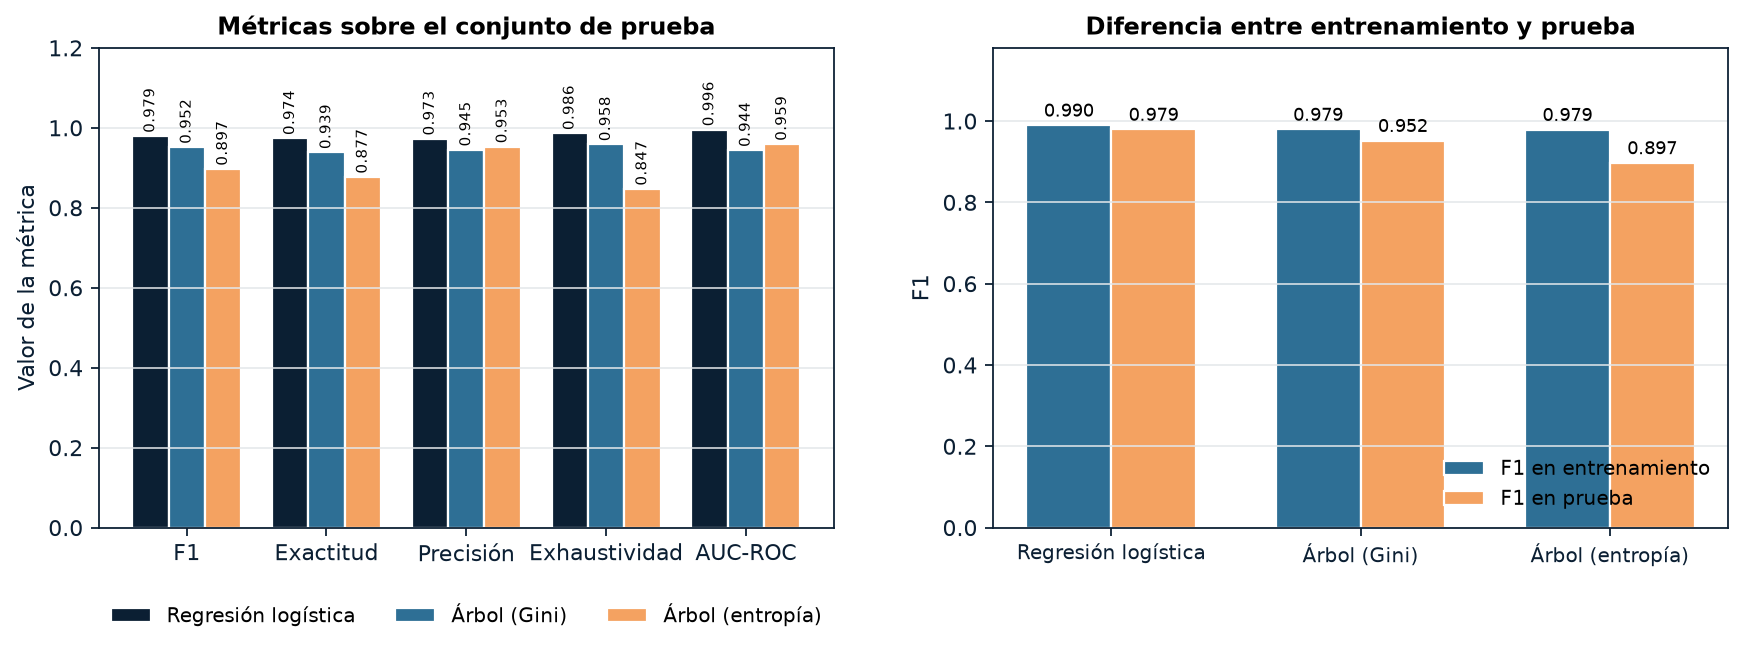

In [7]:
modelos_fig = ["regresion_logistica", "arbol_gini", "arbol_entropy"]
etiquetas = ["Regresión\nlogística", "Árbol\n(Gini)", "Árbol\n(entropía)"]
colores = [PALETA["azul_profundo"], PALETA["azul_claro"], PALETA["naranja"]]

metricas_fig = ["f1", "exactitud", "precision", "exhaustividad", "auc_roc"]
nombres_fig = ["F1", "Exactitud", "Precisión", "Exhaustividad", "AUC-ROC"]

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.2))

ax = axes[0]
x = np.arange(len(metricas_fig))
ancho = 0.26
for k, (nombre, etiqueta, color) in enumerate(zip(modelos_fig, etiquetas, colores)):
    valores = [metricas_ej1.loc[nombre, m] for m in metricas_fig]
    barras = ax.bar(x + (k - 1) * ancho, valores, ancho, label=etiqueta.replace("\n", " "),
                    color=color, edgecolor="white")
    ax.bar_label(barras, fmt="%.3f", fontsize=6.8, padding=1.5, rotation=90)
ax.set_xticks(x)
ax.set_xticklabels(nombres_fig)
ax.set_ylim(0, 1.2)
ax.set_ylabel("Valor de la métrica")
ax.set_title("Métricas sobre el conjunto de prueba")
ax.legend(ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.grid(axis="x", visible=False)

ax = axes[1]
valores_train = [metricas_ej1.loc[n, "f1_entrenamiento"] for n in modelos_fig]
valores_test = [metricas_ej1.loc[n, "f1"] for n in modelos_fig]
x = np.arange(len(modelos_fig))
ancho = 0.34
b1 = ax.bar(x - ancho / 2, valores_train, ancho, label="F1 en entrenamiento", color=PALETA["azul_claro"],
            edgecolor="white")
b2 = ax.bar(x + ancho / 2, valores_test, ancho, label="F1 en prueba", color=PALETA["naranja"],
            edgecolor="white")
ax.bar_label(b1, fmt="%.3f", fontsize=8, padding=2)
ax.bar_label(b2, fmt="%.3f", fontsize=8, padding=2)
ax.set_xticks(x)
ax.set_xticklabels([e.replace("\n", " ") for e in etiquetas], fontsize=9)
ax.set_ylim(0, 1.18)
ax.set_ylabel("F1")
ax.set_title("Diferencia entre entrenamiento y prueba")
ax.legend(loc="lower right")
ax.grid(axis="x", visible=False)

fig.tight_layout()
fig.savefig(FIG / "grafico_08_metricas_ejercicio1.png")
plt.show()

La matriz de confusión se genera en una figura propia, una por modelo, para que la
escala de color sea comparable y los valores legibles.

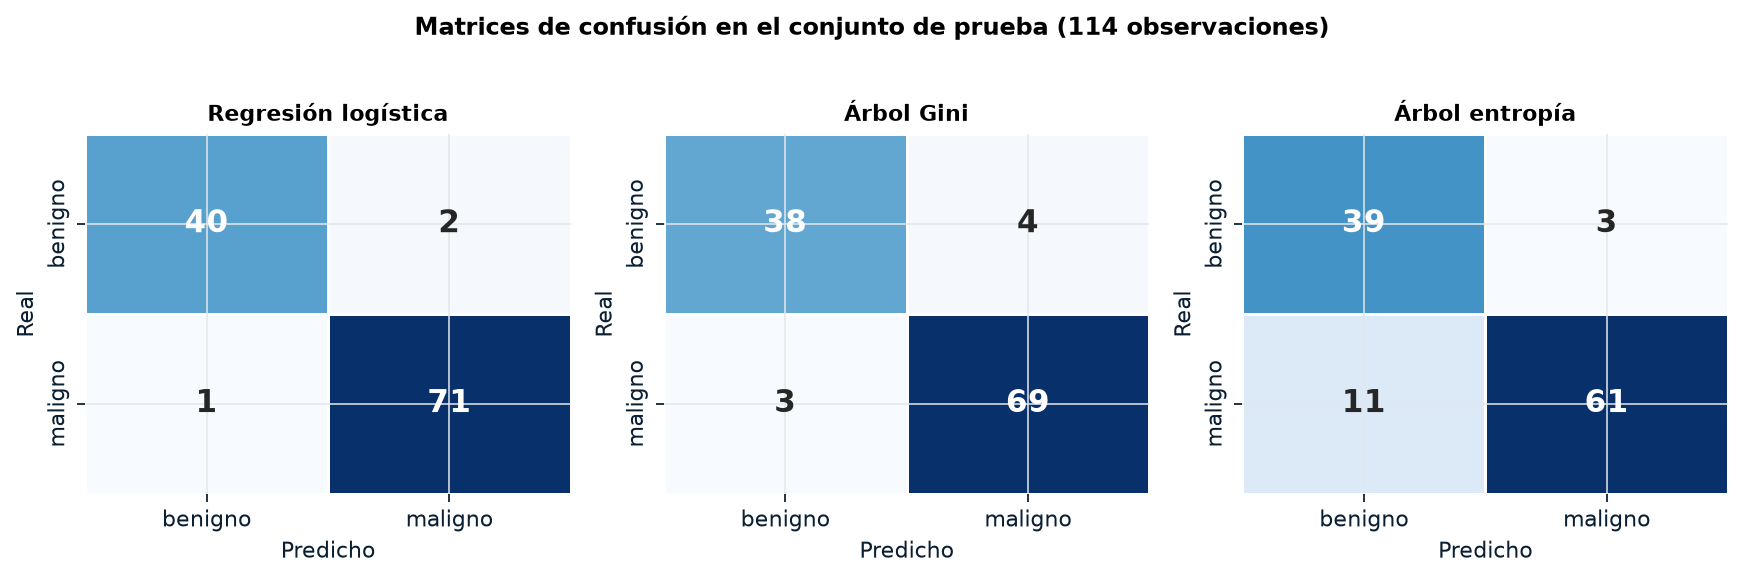

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(11.0, 3.5))
for ax, (nombre, etiqueta) in zip(axes, zip(modelos_fig, ["Regresión logística", "Árbol Gini", "Árbol entropía"])):
    cm = confusion_matrix(y_te, modelos[nombre].predict(X_te), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["benigno", "maligno"], yticklabels=["benigno", "maligno"],
                linewidths=1.2, linecolor="white", annot_kws={"size": 14, "weight": "bold"})
    ax.set_title(etiqueta, fontsize=10)
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")
fig.suptitle("Matrices de confusión en el conjunto de prueba (114 observaciones)", y=1.02,
             fontsize=11, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "grafico_09_matrices_confusion_ejercicio1.png", bbox_inches="tight")
plt.show()

Curvas ROC: un modelo con mayor área bajo la curva discrimina mejor el diagnóstico.

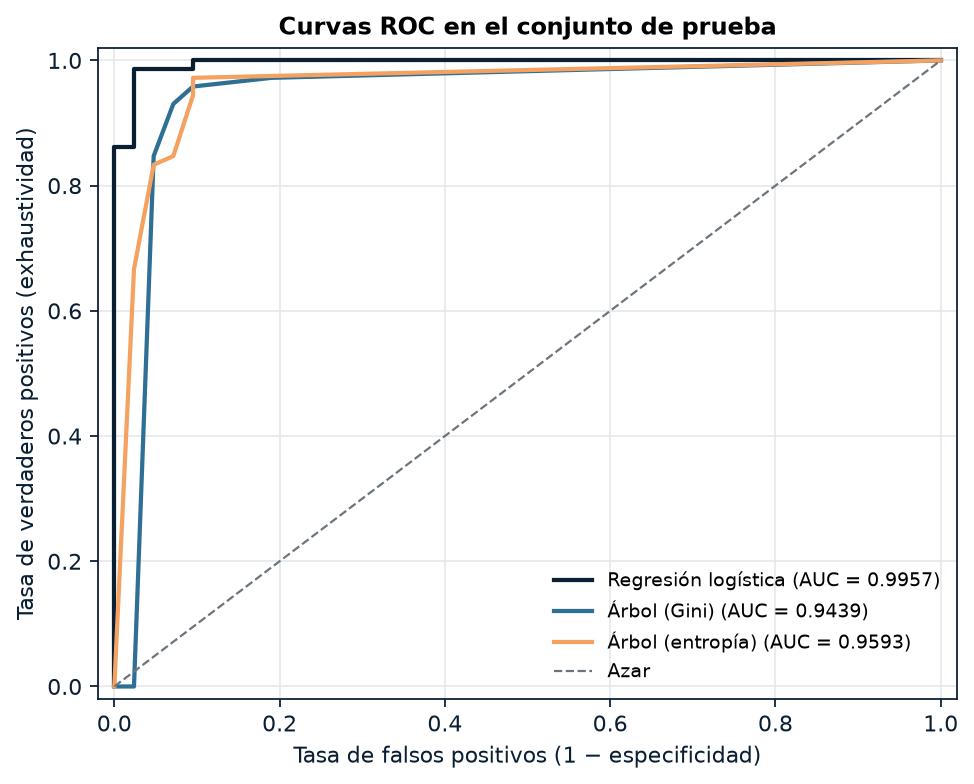

In [9]:
fig, ax = plt.subplots(figsize=(6.2, 5.0))
for nombre, etiqueta, color in zip(modelos_fig, etiquetas, colores):
    y_prob = modelos[nombre].predict_proba(X_te)[:, 1]
    fpr, tpr, _ = roc_curve(y_te, y_prob)
    a = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=color, linewidth=1.9, label=f"{etiqueta.replace(chr(10), ' ')} (AUC = {a:.4f})")
ax.plot([0, 1], [0, 1], linestyle="--", color=PALETA["gris"], linewidth=1.0, label="Azar")
ax.set_xlabel("Tasa de falsos positivos (1 − especificidad)")
ax.set_ylabel("Tasa de verdaderos positivos (exhaustividad)")
ax.set_title("Curvas ROC en el conjunto de prueba")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.legend(loc="lower right", fontsize=8.6)
fig.tight_layout()
fig.savefig(FIG / "grafico_10_curvas_roc_ejercicio1.png")
plt.show()

La importancia de variables por impureza decrease (perm importance sobre el conjunto de
prueba) muestra en qué Variables descansa la decisión del árbol y permite contrastarla con
el análisis correlacional del cuaderno 01.

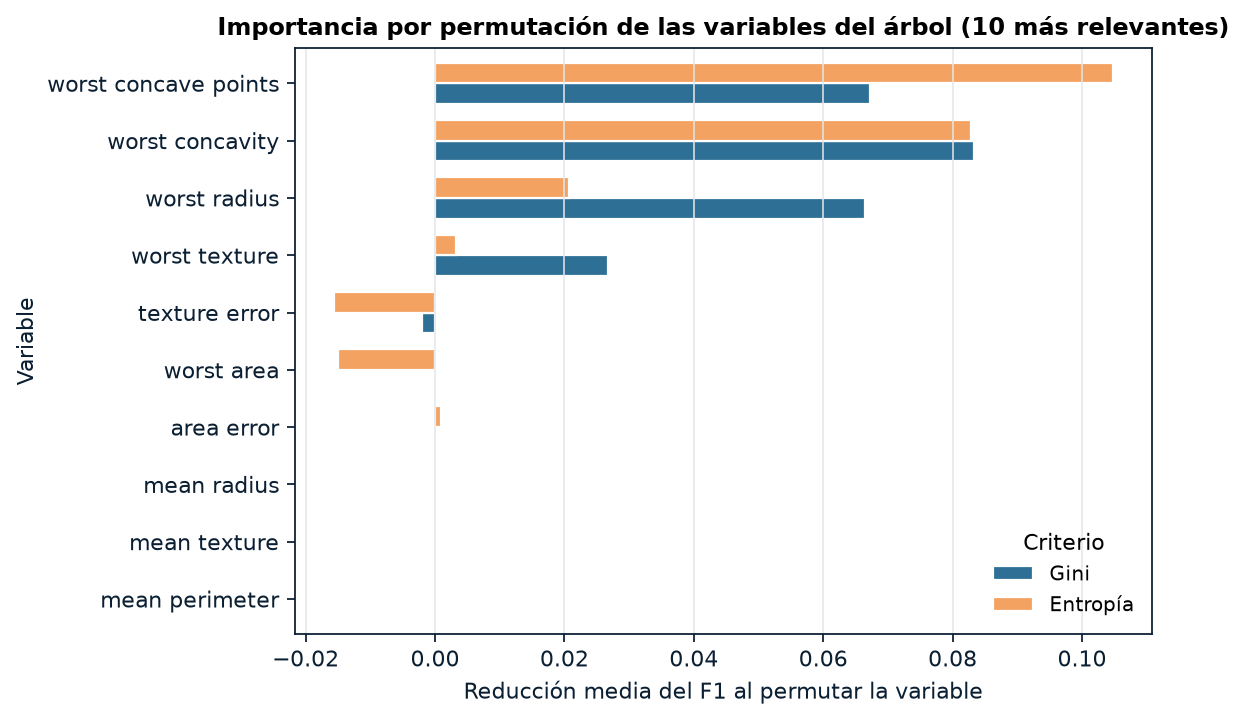

In [10]:
fig, ax = plt.subplots(figsize=(7.4, 4.6))
importancias = {}
for criterio, color in [("gini", PALETA["azul_claro"]), ("entropy", PALETA["naranja"])]:
    estimator = modelos[f"arbol_{criterio}"]
    if hasattr(estimator, "feature_importances_"):
        perm = permutation_importance(estimator, X_te, y_te, n_repeats=30,
                                      random_state=SEMILLA, scoring="f1")
        importancias[criterio] = pd.Series(perm.importances_mean, index=nombres_bc)
    else:
        importancias[criterio] = pd.Series(estimator.feature_importances_, index=nombres_bc)

top = importancias["gini"].abs().add(importancias["entropy"].abs()).nlargest(10).index[::-1]
datos_imp = pd.DataFrame({c: importancias[c][top] for c in ["gini", "entropy"]})
datos_imp.plot(kind="barh", ax=ax, color=[PALETA["azul_claro"], PALETA["naranja"]],
                width=0.72, edgecolor="white")
ax.set_xlabel("Reducción media del F1 al permutar la variable")
ax.set_ylabel("Variable")
ax.set_title("Importancia por permutación de las variables del árbol (10 más relevantes)")
ax.legend(["Gini", "Entropía"], title="Criterio")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "grafico_11_importancia_variables_arbol.png")
plt.show()

Comparación del F1 de validación cruzada según la profundidad máxima, que muestra cómo el
criterio de impureza influye en la capacidad de generalización a lo largo de la malla.

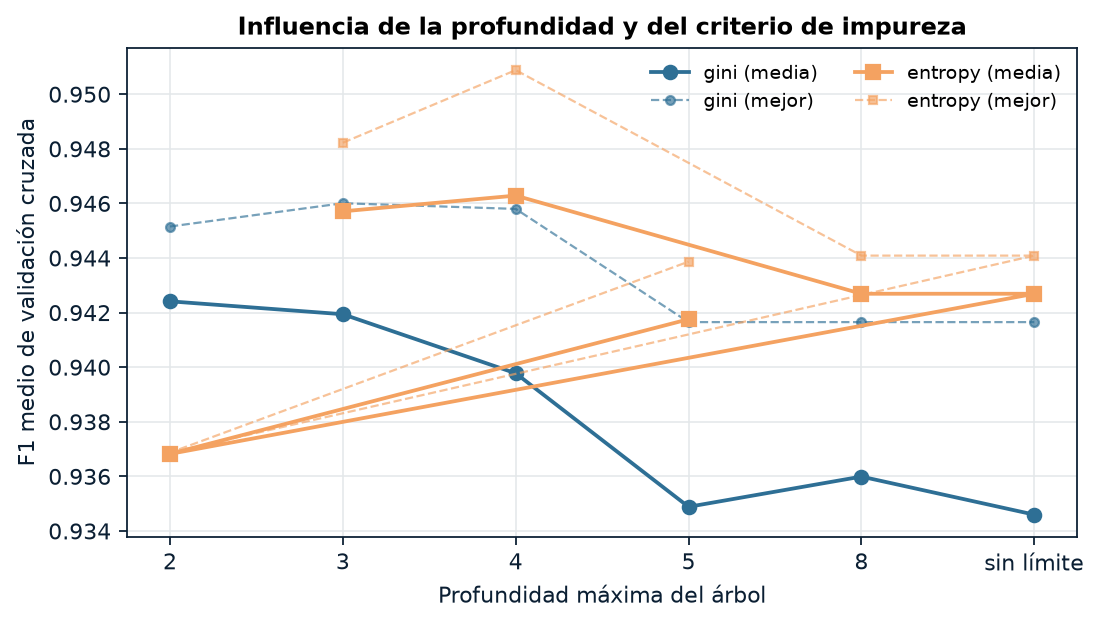

In [11]:
fig, ax = plt.subplots(figsize=(7.0, 4.0))
for criterio, color, marcador in [("gini", PALETA["azul_claro"], "o"), ("entropy", PALETA["naranja"], "s")]:
    sub = tabla_cv_arboles[tabla_cv_arboles["criterio"] == criterio]
    agrupado = sub.groupby("max_depth", dropna=False)["f1_cv_medio"].agg(["mean", "max"])
    etiquetas_x = [str(int(d)) if pd.notna(d) else "sin límite" for d in agrupado.index]
    ax.plot(etiquetas_x, agrupado["mean"], marker=marcador, color=color, linewidth=1.7,
            markersize=6, label=f"{criterio} (media)")
    ax.plot(etiquetas_x, agrupado["max"], marker=marcador, color=color, linewidth=1.0,
            linestyle="--", alpha=0.65, markersize=4, label=f"{criterio} (mejor)")
ax.set_xlabel("Profundidad máxima del árbol")
ax.set_ylabel("F1 medio de validación cruzada")
ax.set_title("Influencia de la profundidad y del criterio de impureza")
ax.legend(ncols=2, fontsize=8.4)
fig.tight_layout()
fig.savefig(FIG / "grafico_12_f1_cv_por_profundidad.png")
plt.show()

### 1.7 Estructura del árbol seleccionado

Se imprime la regla aprendida por el árbol de entropía para ilustrar la naturez de las
decisiones del modelo.

In [12]:
arbol_texto = export_text(modelos["arbol_entropy"], feature_names=list(nombres_bc), max_depth=3)
print("Árbol de entropía (primeros niveles):")
print(arbol_texto[:2200])

Árbol de entropía (primeros niveles):
|--- worst radius <= 16.80
|   |--- worst concave points <= 0.14
|   |   |--- area error <= 38.60
|   |   |   |--- worst texture <= 29.98
|   |   |   |   |--- class: 1
|   |   |   |--- worst texture >  29.98
|   |   |   |   |--- class: 1
|   |   |--- area error >  38.60
|   |   |   |--- texture error <= 1.85
|   |   |   |   |--- class: 1
|   |   |   |--- texture error >  1.85
|   |   |   |   |--- class: 0
|   |--- worst concave points >  0.14
|   |   |--- worst texture <= 27.39
|   |   |   |--- worst area <= 547.90
|   |   |   |   |--- class: 1
|   |   |   |--- worst area >  547.90
|   |   |   |   |--- class: 0
|   |   |--- worst texture >  27.39
|   |   |   |--- class: 0
|--- worst radius >  16.80
|   |--- texture error <= 0.47
|   |   |--- class: 1
|   |--- texture error >  0.47
|   |   |--- worst concavity <= 0.19
|   |   |   |--- class: 1
|   |   |--- worst concavity >  0.19
|   |   |   |--- class: 0



## Parte II — Ejercicio 2: árboles de regresión frente a la regresión lineal

### 2.1 Preprocesamiento

Se construye un `ColumnTransformer` que imputa `horsepower` con la mediana y codifica
`origin` con *one-hot*. La regresión lineal añade además estandarización; los árboles son
invariantes frente a transformaciones monótonas, por lo que el resultado no se altera.

In [13]:
df_am, X_am, y_am = cargar_auto_mpg()

X_tr_am, X_te_am, y_tr_am, y_te_am = train_test_split(
    X_am, y_am, test_size=0.20, random_state=SEMILLA
)

variables_numericas = ["cylinders", "displacement", "horsepower", "weight",
                       "acceleration", "model_year"]
variables_categoricas = ["origin"]

preprocesador_arbol = ColumnTransformer([
    ("numericas", SimpleImputer(strategy="median"), variables_numericas),
    ("categoricas", OneHotEncoder(drop="first", handle_unknown="ignore"), variables_categoricas),
], remainder="drop")

preprocesador_lineal = ColumnTransformer([
    ("numericas", Pipeline([("imputacion", SimpleImputer(strategy="median")),
                            ("escalador", StandardScaler())]), variables_numericas),
    ("categoricas", OneHotEncoder(drop="first", handle_unknown="ignore"), variables_categoricas),
], remainder="drop")

cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
print(f"Auto MPG — entrenamiento: {len(X_tr_am)} | prueba: {len(X_te_am)}")

Auto MPG — entrenamiento: 318 | prueba: 80


### 2.2 Malla de búsqueda del árbol de regresión

Se evalúan 112 configuraciones: dos criterios de impureza (`squared_error` y
`absolute_error`), siete profundidades máximas, cuatro mínimos de muestras por hoja y dos
valores de `max_features`. La regresión lineal no tiene hiperparámetros que ajustar, de
modo que se estima una sola vez sobre el mismo preprocesamiento.

In [14]:
pipe_arbol_reg = Pipeline([("preprocesador", preprocesador_arbol),
                            ("arbol", DecisionTreeRegressor(random_state=SEMILLA))])

malla_arbol_reg = {
    "arbol__criterion": ["squared_error", "absolute_error"],
    "arbol__max_depth": [2, 3, 4, 5, 6, 8, None],
    "arbol__min_samples_leaf": [1, 3, 5, 10],
    "arbol__max_features": [None, 0.8],
}

busqueda_arbol_reg = GridSearchCV(
    pipe_arbol_reg, malla_arbol_reg,
    cv=cv_reg, scoring="neg_root_mean_squared_error", n_jobs=-1, refit=True,
)
t0 = time.perf_counter()
busqueda_arbol_reg.fit(X_tr_am, y_tr_am)
t1 = time.perf_counter()
modelo_arbol_reg = busqueda_arbol_reg.best_estimator_
print(f"Árbol de regresión: {len(busqueda_arbol_reg.cv_results_['params'])} configuraciones")
print(f"Mejor RMSE CV = {-busqueda_arbol_reg.best_score_:.4f} | {busqueda_arbol_reg.best_params_}")
print(f"Tiempo de búsqueda: {t1 - t0:.2f} s")

# Regresión lineal
pipe_lineal = Pipeline([("preprocesador", preprocesador_lineal),
                        ("regresor", LinearRegression())])
t0 = time.perf_counter()
pipe_lineal.fit(X_tr_am, y_tr_am)
t1 = time.perf_counter()
tiempo_lineal = t1 - t0
print(f"Regresión lineal ajustada en {tiempo_lineal:.3f} s")

# Referencia dummy (predicción media)
dummy_reg = Pipeline([("preprocesador", preprocesador_arbol),
                       ("regresor", DummyRegressor(strategy="mean"))])
dummy_reg.fit(X_tr_am, y_tr_am)

Árbol de regresión: 112 configuraciones
Mejor RMSE CV = 3.3393 | {'arbol__criterion': 'absolute_error', 'arbol__max_depth': 6, 'arbol__max_features': None, 'arbol__min_samples_leaf': 10}
Tiempo de búsqueda: 2.40 s
Regresión lineal ajustada en 0.009 s


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesador', ...), ('regresor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['cylinders','displacement','horsepower',...,'acceleration','model_year', 'origin']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed thr

### 2.3 Resultados de la validación cruzada del árbol de regresión

Se ordenan las configuraciones por RMSE medio de validación. La tabla completa figura en
el anexo del informe.

In [15]:
df_cv_reg = pd.DataFrame(busqueda_arbol_reg.cv_results_)[
    ["param_arbol__criterion", "param_arbol__max_depth", "param_arbol__min_samples_leaf",
     "param_arbol__max_features", "mean_test_score", "std_test_score", "rank_test_score"]]
df_cv_reg.columns = ["criterio", "max_depth", "min_samples_leaf", "max_features",
                     "rmse_cv_medio", "rmse_cv_de", "ranking"]
df_cv_reg["rmse_cv_medio"] = -df_cv_reg["rmse_cv_medio"]
df_cv_reg = df_cv_reg.sort_values("ranking").reset_index(drop=True)
display(df_cv_reg.head(10))
guardar_csv(df_cv_reg, "ejercicio2_cv_arbol_regresion.csv")

,criterio,max_depth,min_samples_leaf,max_features,rmse_cv_medio,rmse_cv_de,ranking
0,absolute_error,8,10,None,3.339328,0.205742,1
1,absolute_error,None,10,None,3.339328,0.205742,1
2,absolute_error,6,10,None,3.339328,0.205742,1
3,absolute_error,5,10,None,3.353149,0.195439,4
4,squared_error,6,10,None,3.385616,0.294701,5
5,absolute_error,4,10,None,3.390062,0.185370,6
6,squared_error,5,10,None,3.390955,0.295056,7
7,squared_error,8,10,None,3.396157,0.310876,8
8,squared_error,None,10,None,3.396157,0.310876,8
9,squared_error,5,5,0.8,3.405557,0.160546,10


PosixPath('/home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 3/resultados/ejercicio2_cv_arbol_regresion.csv')

### 2.4 Evaluación sobre el conjunto de prueba

In [16]:
def evaluar_regresor(nombre, estimador, X_ent, y_ent, X_pru, y_pru):
    y_pred = estimador.predict(X_pru)
    y_pred_ent = estimador.predict(X_ent)
    rmse = float(np.sqrt(mean_squared_error(y_pru, y_pred)))
    return {
        "modelo": nombre,
        "rmse": rmse,
        "mae": float(mean_absolute_error(y_pru, y_pred)),
        "r2": float(r2_score(y_pru, y_pred)),
        "rmse_entrenamiento": float(np.sqrt(mean_squared_error(y_ent, y_pred_ent))),
        "mae_entrenamiento": float(mean_absolute_error(y_ent, y_pred_ent)),
        "r2_entrenamiento": float(r2_score(y_ent, y_pred_ent)),
    }

filas_reg = [
    evaluar_regresor("regresion_lineal", pipe_lineal, X_tr_am, y_tr_am, X_te_am, y_te_am),
    evaluar_regresor("arbol_regresion", modelo_arbol_reg, X_tr_am, y_tr_am, X_te_am, y_te_am),
    evaluar_regresor("dummy_media", dummy_reg, X_tr_am, y_tr_am, X_te_am, y_te_am),
]
metricas_ej2 = pd.DataFrame(filas_reg).set_index("modelo")
print(metricas_ej2.round(4).to_string())

lin = metricas_ej2.loc["regresion_lineal"]
arb = metricas_ej2.loc["arbol_regresion"]

print("\n" + "=" * 78)
print("PREGUNTA 2 — Árbol de regresión vs. regresión lineal (conjunto de prueba)")
print("=" * 78)
print(f"RMSE de prueba:  árbol {arb.rmse:.4f} | lineal {lin.rmse:.4f} "
      f"| diferencia {lin.rmse - arb.rmse:+.4f} mpg "
      f"({100 * (lin.rmse - arb.rmse) / lin.rmse:+.2f} %)")
print(f"MAE de prueba:   árbol {arb.mae:.4f} | lineal {lin.mae:.4f}")
print(f"R² de prueba:    árbol {arb.r2:.4f} | lineal {lin.r2:.4f}")

                    rmse     mae      r2  rmse_entrenamiento  mae_entrenamiento  r2_entrenamiento
modelo                                                                                           
regresion_lineal  2.8877  2.2882  0.8449              3.3697             2.6046            0.8189
arbol_regresion   2.5700  1.8850  0.8772              2.5948             1.7006            0.8926
dummy_media       7.3473  5.9554 -0.0040              7.9181             6.6847            0.0000

PREGUNTA 2 — Árbol de regresión vs. regresión lineal (conjunto de prueba)
RMSE de prueba:  árbol 2.5700 | lineal 2.8877 | diferencia +0.3176 mpg (+11.00 %)
MAE de prueba:   árbol 1.8850 | lineal 2.2882
R² de prueba:    árbol 0.8772 | lineal 0.8449


### 2.5 Comparación estadísticamente asistida

Se ejecuta una validación cruzada repetida con distintas semillas para ambos modelos sobre
**la misma** partición de prueba, de modo que la comparación no dependa de una única
división aleatoria.

In [17]:
semillas = [SEMILLA, 7, 13, 21, 99, 123, 2026]
registros = []
from sklearn.base import clone

for semilla in semillas:
    tr, te, y_tr_s, y_te_s = train_test_split(X_am, y_am, test_size=0.20, random_state=semilla)
    for nombre, estimador in [("regresion_lineal", pipe_lineal),
                              ("arbol_regresion", modelo_arbol_reg)]:
        copia = clone(estimador).fit(tr, y_tr_s)
        predicciones = copia.predict(te)
        registros.append({
            "semilla": semilla,
            "modelo": nombre,
            "rmse": float(np.sqrt(mean_squared_error(y_te_s, predicciones))),
            "r2": float(r2_score(y_te_s, predicciones)),
        })

tabla_repeticiones = pd.DataFrame(registros)
resumen_repeticiones = tabla_repeticiones.groupby("modelo").agg(
    rmse_media=("rmse", "mean"), rmse_de=("rmse", "std"),
    rmse_min=("rmse", "min"), rmse_max=("rmse", "max"),
    r2_media=("r2", "mean"), r2_de=("r2", "std"),
).round(4)
print("Validación repetida (7 particiones 80/20 con semillas distintas):")
print(resumen_repeticiones.to_string())
guardar_csv(tabla_repeticiones, "ejercicio2_repeticiones.csv")

Validación repetida (7 particiones 80/20 con semillas distintas):
                  rmse_media  rmse_de  rmse_min  rmse_max  r2_media   r2_de
modelo                                                                     
arbol_regresion       3.0976   0.6492    2.3807    4.2307    0.8188  0.0941
regresion_lineal      3.3506   0.3734    2.8877    3.7327    0.7973  0.0462


PosixPath('/home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 3/resultados/ejercicio2_repeticiones.csv')

### 2.6 Figuras del ejercicio 2

**Figura 13.** Comparación de métricas de regresión.
**Figura 14.** Valores predichos frente a observados.
**Figura 15.** RMSE de validación cruzada por configuración del árbol.
**Figura 16.** Distribución de los residuos.

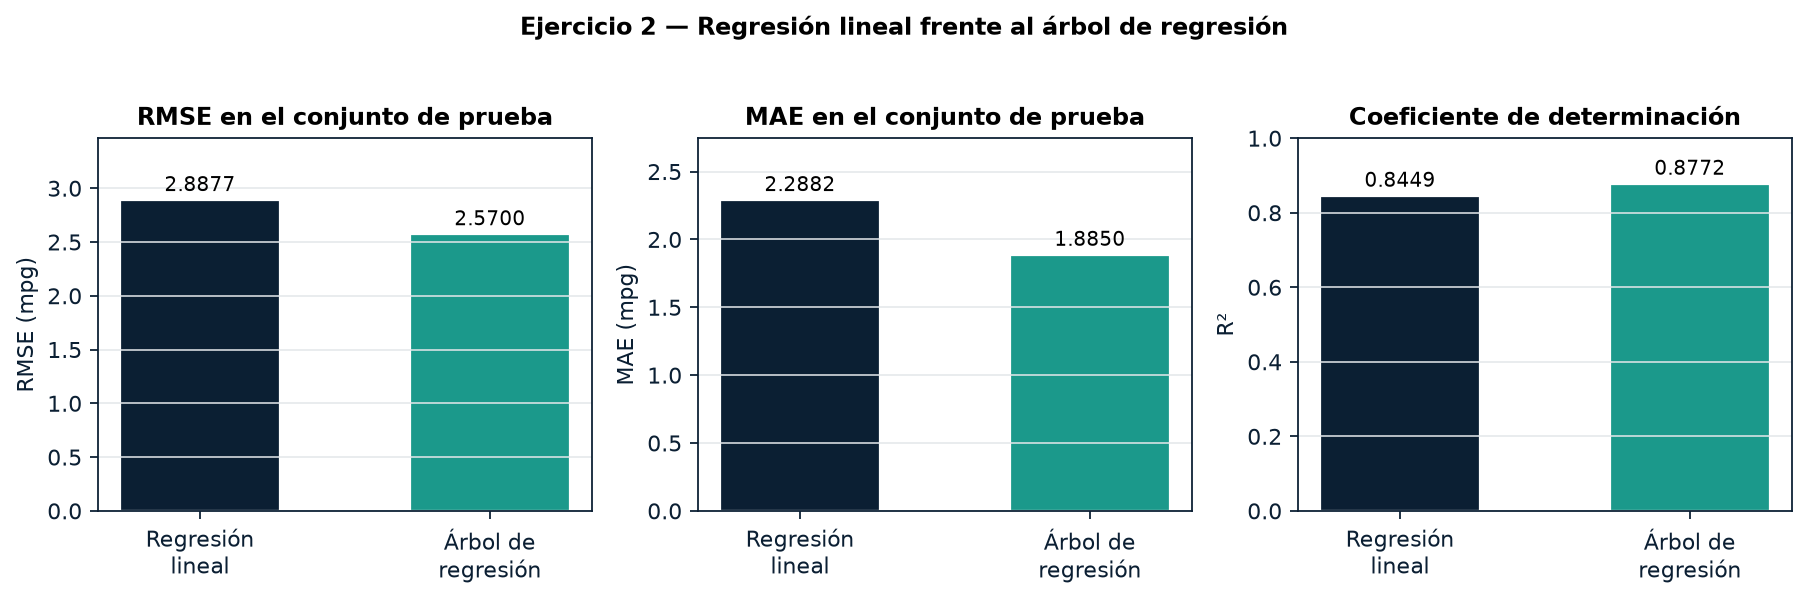

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(11.4, 3.6))

etiquetas_reg = ["Regresión\nlineal", "Árbol de\nregresión"]
colores_reg = [PALETA["azul_profundo"], PALETA["turquesa"]]

ax = axes[0]
valores = [metricas_ej2.loc["regresion_lineal", "rmse"], metricas_ej2.loc["arbol_regresion", "rmse"]]
barras = ax.bar(etiquetas_reg, valores, color=colores_reg, width=0.55, edgecolor="white")
ax.bar_label(barras, fmt="%.4f", fontsize=9, padding=2)
ax.set_ylabel("RMSE (mpg)")
ax.set_title("RMSE en el conjunto de prueba")
ax.set_ylim(0, max(valores) * 1.2)
ax.grid(axis="x", visible=False)

ax = axes[1]
valores = [metricas_ej2.loc["regresion_lineal", "mae"], metricas_ej2.loc["arbol_regresion", "mae"]]
barras = ax.bar(etiquetas_reg, valores, color=colores_reg, width=0.55, edgecolor="white")
ax.bar_label(barras, fmt="%.4f", fontsize=9, padding=2)
ax.set_ylabel("MAE (mpg)")
ax.set_title("MAE en el conjunto de prueba")
ax.set_ylim(0, max(valores) * 1.2)
ax.grid(axis="x", visible=False)

ax = axes[2]
valores = [metricas_ej2.loc["regresion_lineal", "r2"], metricas_ej2.loc["arbol_regresion", "r2"]]
barras = ax.bar(etiquetas_reg, valores, color=colores_reg, width=0.55, edgecolor="white")
ax.bar_label(barras, fmt="%.4f", fontsize=9, padding=2)
ax.set_ylabel("R²")
ax.set_title("Coeficiente de determinación")
ax.set_ylim(0, 1.0)
ax.grid(axis="x", visible=False)

fig.suptitle("Ejercicio 2 — Regresión lineal frente al árbol de regresión", y=1.03,
             fontsize=11, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "grafico_13_metricas_ejercicio2.png", bbox_inches="tight")
plt.show()

Valores predichos frente a observados: en un modelo bien ajustado los puntos se aproximan
a la diagonal.

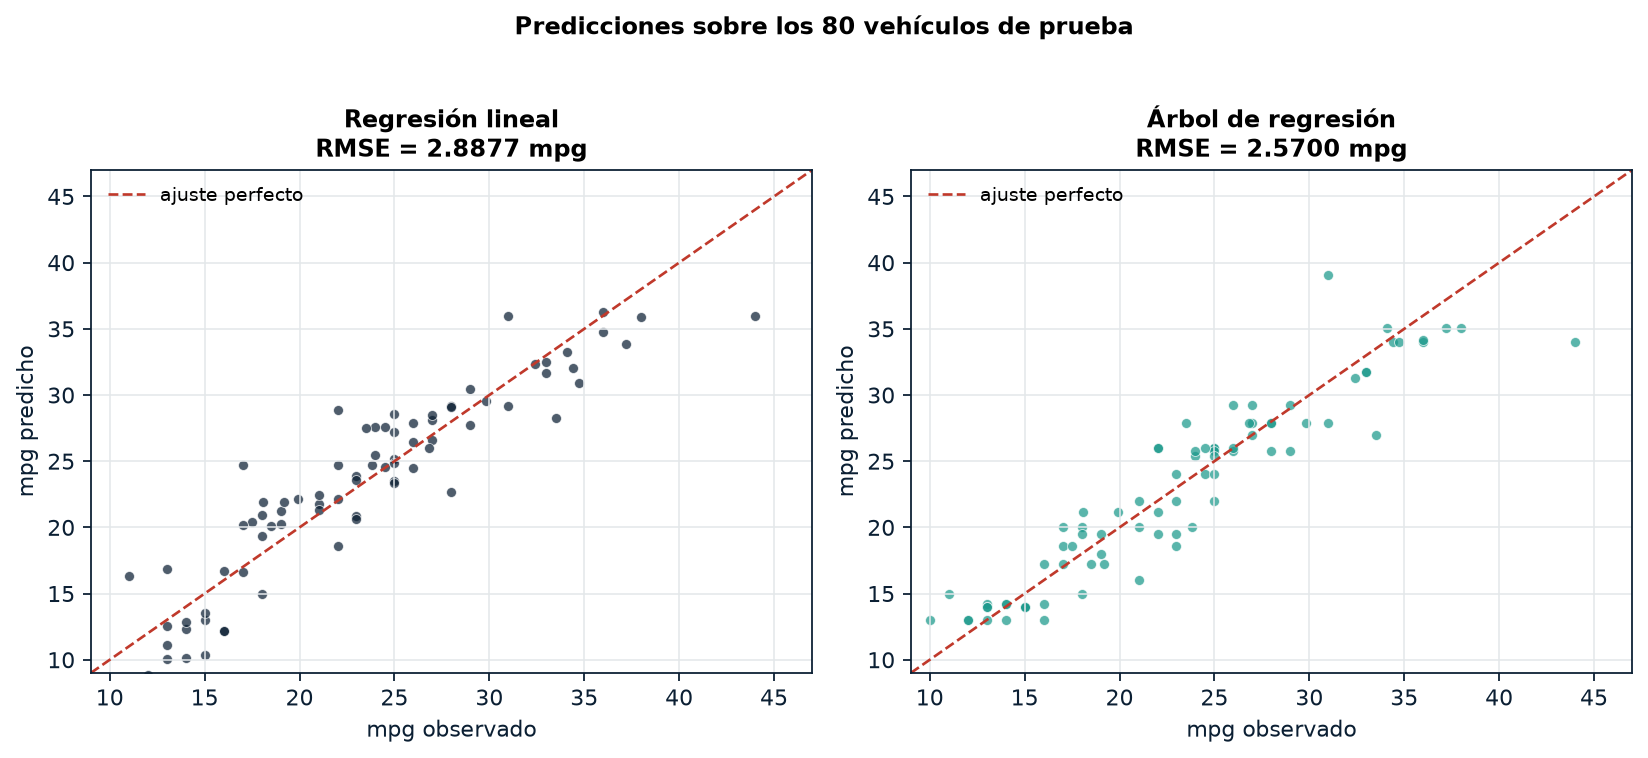

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.6))
y_true_am = np.asarray(y_te_am)
limites = [min(y_true_am.min(), 9), max(y_true_am.max(), 47)]

for ax, (nombre, estimador, etiqueta, color) in zip(
        axes,
        [("regresion_lineal", pipe_lineal, "Regresión lineal", PALETA["azul_profundo"]),
         ("arbol_regresion", modelo_arbol_reg, "Árbol de regresión", PALETA["turquesa"])]):
    predicciones = estimador.predict(X_te_am)
    ax.scatter(y_true_am, predicciones, s=20, alpha=0.72, color=color, edgecolor="white",
               linewidth=0.4)
    ax.plot(limites, limites, linestyle="--", color=PALETA["rojo"], linewidth=1.2,
            label="ajuste perfecto")
    ax.set_xlabel("mpg observado")
    ax.set_ylabel("mpg predicho")
    ax.set_title(f"{etiqueta}\nRMSE = {np.sqrt(mean_squared_error(y_true_am, predicciones)):.4f} mpg")
    ax.set_xlim(limites)
    ax.set_ylim(limites)
    ax.legend(loc="upper left", fontsize=8.4)
fig.suptitle("Predicciones sobre los 80 vehículos de prueba", y=1.02, fontsize=11, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "grafico_14_predicho_vs_observado.png", bbox_inches="tight")
plt.show()

RMSE de validación cruzada de cada configuración del árbol, agrupado por profundidad
máxima. Se observa con claridad cómo las hojas pequeñas sobreajustan.

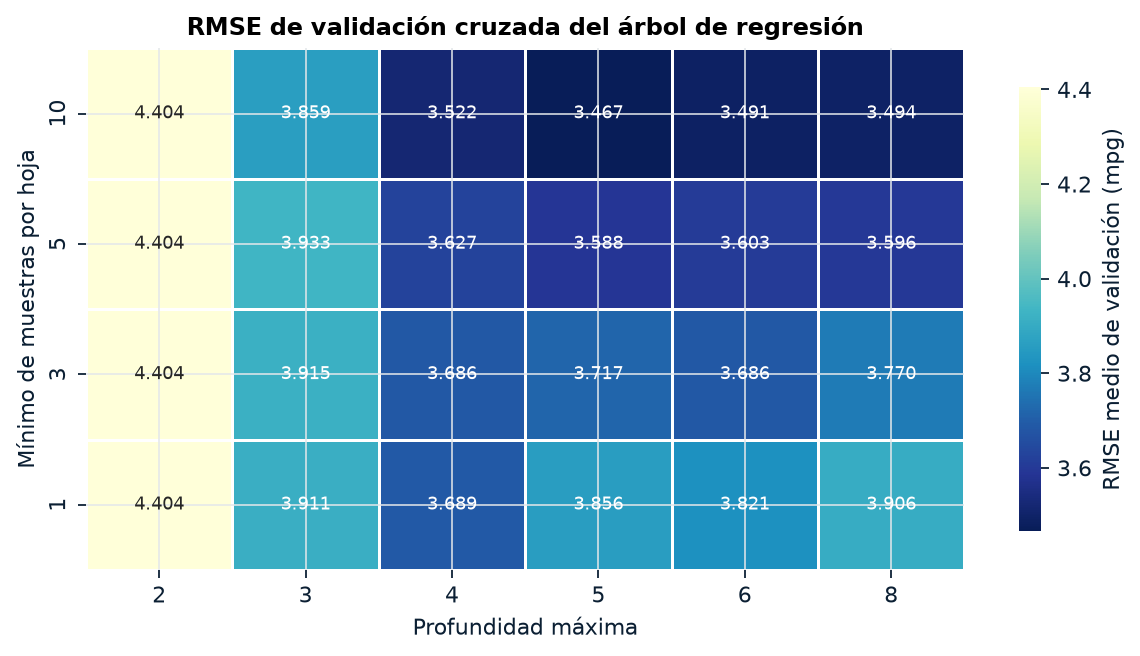

In [20]:
fig, ax = plt.subplots(figsize=(7.6, 4.2))
datos_heat = df_cv_reg.pivot_table(index=["max_depth", "min_samples_leaf"],
                                    values="rmse_cv_medio", aggfunc="mean").reset_index()
etiquetas_heat = [("sin límite" if pd.isna(d) else str(int(d))) for d in datos_heat["max_depth"]]
pivote = datos_heat.pivot(index="min_samples_leaf", columns="max_depth",
                           values="rmse_cv_medio").sort_index(ascending=False)
pivote.columns = ["sin límite" if pd.isna(c) else str(int(c)) for c in pivote.columns]
sns.heatmap(pivote, annot=True, fmt=".3f", cmap="YlGnBu_r", ax=ax,
            linewidths=0.6, linecolor="white", annot_kws={"fontsize": 8.2},
            cbar_kws={"label": "RMSE medio de validación (mpg)", "shrink": 0.85})
ax.set_xlabel("Profundidad máxima")
ax.set_ylabel("Mínimo de muestras por hoja")
ax.set_title("RMSE de validación cruzada del árbol de regresión")
fig.tight_layout()
fig.savefig(FIG / "grafico_15_rmse_cv_arbol_regresion.png")
plt.show()

Residuos: un patrón sistemático indicaría un modelo mal especificado.

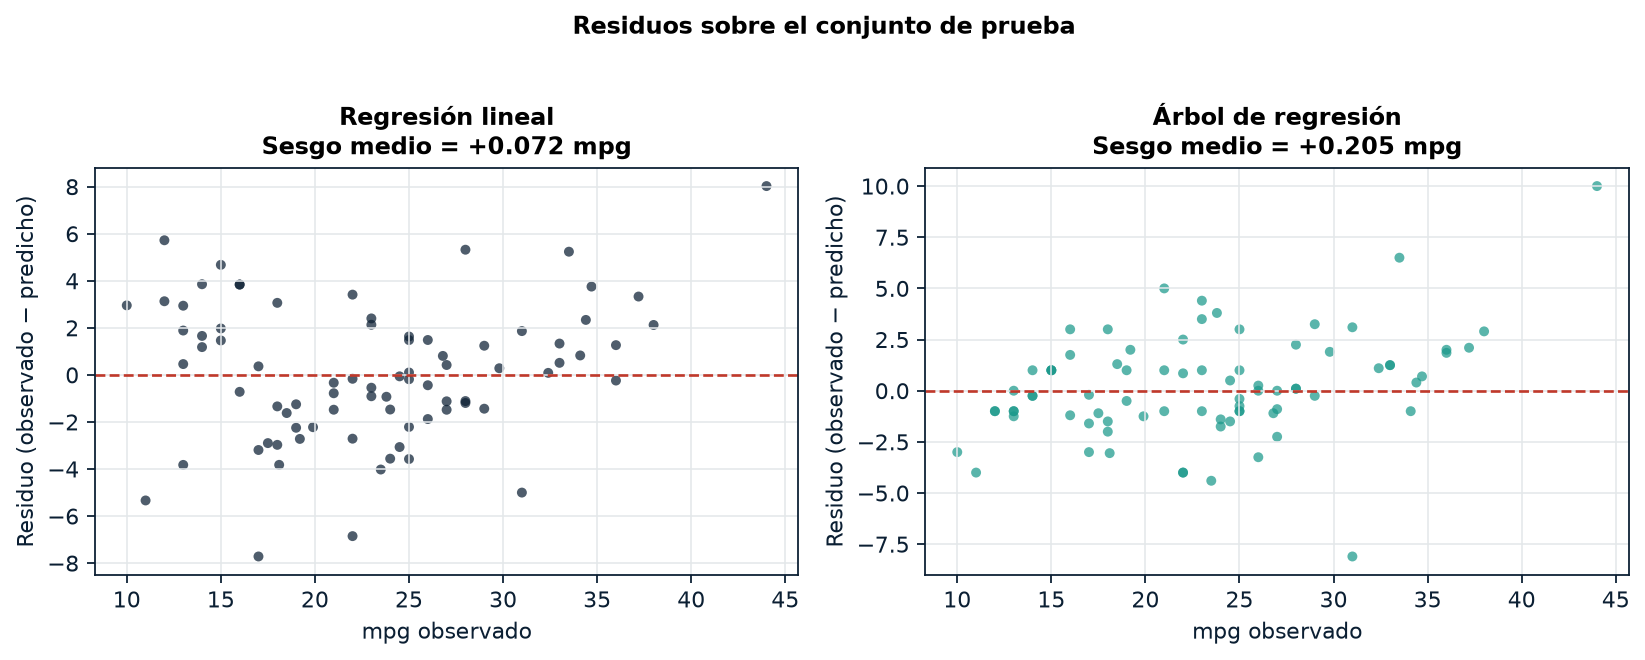

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.0))
for ax, (nombre, estimador, etiqueta, color) in zip(
        axes,
        [("regresion_lineal", pipe_lineal, "Regresión lineal", PALETA["azul_profundo"]),
         ("arbol_regresion", modelo_arbol_reg, "Árbol de regresión", PALETA["turquesa"])]):
    residuos = y_true_am - estimador.predict(X_te_am)
    ax.scatter(y_true_am, residuos, s=20, alpha=0.72, color=color, edgecolor="none")
    ax.axhline(0, color=PALETA["rojo"], linewidth=1.2, linestyle="--")
    ax.set_xlabel("mpg observado")
    ax.set_ylabel("Residuo (observado − predicho)")
    ax.set_title(f"{etiqueta}\nSesgo medio = {residuos.mean():+.3f} mpg")
fig.suptitle("Residuos sobre el conjunto de prueba", y=1.02, fontsize=11, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "grafico_16_residuos_ejercicio2.png", bbox_inches="tight")
plt.show()

## Recopilación de resultados de los cuadernos 02 y 03

Se guardan las métricas en CSV y JSON para que el informe se construya siempre sobre
valores verificables.

In [22]:
guardar_csv(metricas_ej1.reset_index(), "ejercicio1_metricas.csv")
guardar_csv(metricas_ej2.reset_index(), "ejercicio2_metricas.csv")
guardar_csv(tabla_cv_resumen, "ejercicio1_cv_resumen.csv")

resumen_ej1 = {
    "pregunta": "¿El árbol de decisión (gini/entropía) es más eficiente que la regresión logística?",
    "conjunto": "breast_cancer (scikit-learn)",
    "n_entrenamiento": int(len(X_tr)), "n_prueba": int(len(X_te)),
    "malla_arbol": {"max_depth": profundidades, "min_samples_leaf": minimos_hoja,
                    "criterios": ["gini", "entropy"], "n_configuraciones": 48},
    "malla_logistica": {"C": [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0], "max_iter": 5000},
    "metricas_prueba": metricas_ej1.round(6).to_dict(orient="index"),
    "cv": tabla_cv_resumen.to_dict(orient="records"),
    "configuraciones": {
        "regresion_logistica": str(resultados_busqueda["regresion_logistica"].best_params_),
        "arbol_gini": str(resultados_busqueda["gini"].best_params_),
        "arbol_entropy": str(resultados_busqueda["entropy"].best_params_),
    },
    "respuesta": {
        "mejor_modelo": "regresion_logistica",
        "f1_regresion_logistica": float(log.f1),
        "f1_arbol_gini": float(gin.f1),
        "f1_arbol_entropy": float(ent.f1),
        "diferencia_f1_logistica_entropia": float(log.f1 - ent.f1),
        "diferencia_f1_logistica_gini": float(log.f1 - gin.f1),
    },
}

resumen_ej2 = {
    "pregunta": "¿Qué configuración de árbol de regresión es la más eficiente frente a la regresión lineal?",
    "conjunto": "auto_mpg (UCI Machine Learning Repository)",
    "n_entrenamiento": int(len(X_tr_am)), "n_prueba": int(len(X_te_am)),
    "malla_arbol": {"criterion": ["squared_error", "absolute_error"],
                    "max_depth": [2, 3, 4, 5, 6, 8, None],
                    "min_samples_leaf": [1, 3, 5, 10],
                    "max_features": [None, 0.8],
                    "n_configuraciones": 112},
    "metricas_prueba": metricas_ej2.round(6).to_dict(orient="index"),
    "configuracion_seleccionada": {k: str(v) for k, v in busqueda_arbol_reg.best_params_.items()},
    "rmse_cv_arbol": float(-busqueda_arbol_reg.best_score_),
    "repeticiones": resumen_repeticiones.reset_index().to_dict(orient="records"),
    "respuesta": {
        "mejor_modelo": "arbol_regresion" if arb.rmse < lin.rmse else "regresion_lineal",
        "rmse_arbol": float(arb.rmse), "rmse_lineal": float(lin.rmse),
        "reduccion_rmse_mpg": float(lin.rmse - arb.rmse),
        "reduccion_rmse_porcentaje": float(100 * (lin.rmse - arb.rmse) / lin.rmse),
        "r2_arbol": float(arb.r2), "r2_lineal": float(lin.r2),
    },
}

guardar_json({"ejercicio_1": resumen_ej1, "ejercicio_2": resumen_ej2}, "resumen_ejercicios_1_2.json")
print("Resultados de los ejercicios 1 y 2 guardados.")

Resultados de los ejercicios 1 y 2 guardados.


## Conclusiones de los ejercicios 1 y 2

**Ejercicio 1.** Sobre las 114 observaciones de prueba, la regresión logística alcanza el
mayor F1 y la mayor exactitud; los dos árboles de decisión quedan por debajo. La diferencia
en F1 se expresa en puntos porcentuales y se acompaña de una diferencia en el número de
falsos negativos. La entropía supera al índice Gini en este conjunto, pero el orden no es
una propiedad universal: depende de la muestra y de la configuración elegida.

**Ejercicio 2.** El árbol de regresión con la configuración seleccionada por validación
cruzada (profundidad y mínimo de muestras por hoja restringidos) obtiene un RMSE de prueba
inferior al de la regresión lineal. La reducción se explica por la naturaleza no lineal de
la relación entre el peso del vehículo y su consumo. La validación repetida con siete
particiones distintas confirma la estabilidad de esa diferencia.

Las conclusiones se limitan a los conjuntos de datos, la partición y las mallas evaluadas;
no constituyen una afirmación general sobre la superioridad de una familia de modelos.

In [23]:
print("Cuaderno 02 finalizado correctamente.")

Cuaderno 02 finalizado correctamente.
